**Setup**

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib
REPO = "/content/anomaly-mvtec"
if not os.path.exists(REPO):
    !git clone https://github.com/maha-mrrk/anomaly-mvtec.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
if REPO not in sys.path:
    sys.path.append(REPO)
importlib.invalidate_caches()          # prend en compte les nouveaux fichiers après un pull
!pip install -q -r requirements.txt

from src.config import *
set_seed(42)
prepare_data()
print(device, DATA_ROOT)

Mounted at /content/drive
Cloning into '/content/anomaly-mvtec'...
remote: Enumerating objects: 78, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 78 (delta 25), reused 61 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (78/78), 14.03 MiB | 32.64 MiB/s, done.
Resolving deltas: 100% (25/25), done.
/content/anomaly-mvtec
Données prêtes : ['carpet', 'screw', 'cable']
cuda /content/mvtec


In [4]:
import torch, numpy as np
from src.data import *
from src.scoring import *
from src.metrics import *

**Cellule 2 : imports et configuration**

In [7]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from src.data import *
from src.scoring import *
from src.models.dino import DinoDetector

SIGMA, K_MAIN, IMG_SIZE = 4, 1, 224
SEEDS = range(5)                                   # 5 découpages calibration/évaluation
MODELS = {"DINO": "dino", "VAE": "vae"}
RES_DIR = f"{REPO}/results"; os.makedirs(RES_DIR, exist_ok=True)

def load_scores(prefix, cat):
    z = np.load(f"{CKPT_DIR}/{prefix}_scores_{cat}.npz")
    return z["labels"], z["test_scores"], z["val_scores"]

In [8]:
!ls {CKPT_DIR} | grep -E "dino_scores|vae_scores"

dino_scores_cable.npz
dino_scores_carpet.npz
dino_scores_screw.npz
vae_scores_cable.npz
vae_scores_carpet.npz
vae_scores_screw.npz


**Cellule 3 : fonctions**

In [9]:
def decision_report(y, s, thr):
    pred = s > thr
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn)
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return dict(thr=float(thr), TPR=rec, FPR=fp / (fp + tn), precision=prec, F1=f1,
                TN=tn, FP=fp, FN=fn, TP=tp)

def ece(y, p, n_bins=5):
    edges, tot = np.linspace(0, 1, n_bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p <= hi) if lo == 0 else (p > lo) & (p <= hi)
        if m.any():
            tot += m.mean() * abs(y[m].mean() - p[m].mean())
    return tot

**Cellule 4 : seuils et calibration**

In [10]:
rows_dec, rows_cal, CURVES = [], [], {}
for name, pre in MODELS.items():
    for cat in CATEGORIES:
        y, s, v = load_scores(pre, cat)
        for seed in SEEDS:
            ic, ie = train_test_split(np.arange(len(y)), test_size=0.5, stratify=y, random_state=seed)
            yc, sc, ye, se = y[ic], s[ic], y[ie], s[ie]

            # (a) trois règles de seuil, toutes évaluées sur la moitié évaluation
            fpr, tpr, th = roc_curve(yc, sc)
            rules = {"P95(val_normal)": np.percentile(v, 95),
                     "P99(val_normal)": np.percentile(v, 99),
                     "Youden(calib)": th[np.argmax(tpr - fpr)]}
            for rule, thr in rules.items():
                rows_dec.append({"model": name, "category": cat, "rule": rule, "seed": seed,
                                 **decision_report(ye, se, thr)})

            # (b) probabilités : score min-max brut vs régression logistique (Platt)
            p_raw = np.clip((se - sc.min()) / (sc.max() - sc.min() + 1e-12), 0, 1)
            mu, sd = sc.mean(), sc.std() + 1e-12
            platt = LogisticRegression(C=10.0, max_iter=1000).fit(((sc - mu) / sd).reshape(-1, 1), yc)
            p_cal = platt.predict_proba(((se - mu) / sd).reshape(-1, 1))[:, 1]
            rows_cal.append({"model": name, "category": cat, "seed": seed,
                             "ECE_brut": ece(ye, p_raw), "ECE_Platt": ece(ye, p_cal),
                             "Brier_brut": brier_score_loss(ye, p_raw),
                             "Brier_Platt": brier_score_loss(ye, p_cal)})
            if seed == 0:
                CURVES[(name, cat)] = (ye, p_raw, p_cal)

dec = (pd.DataFrame(rows_dec).groupby(["model", "category", "rule"]).mean(numeric_only=True)
       .drop(columns="seed").round(3))
cal = (pd.DataFrame(rows_cal).groupby(["model", "category"]).mean(numeric_only=True)
       .drop(columns="seed").round(3))
dec.to_csv(f"{RES_DIR}/t9_thresholds.csv"); cal.to_csv(f"{RES_DIR}/t9_calibration.csv")
dec

thr    TPR    FPR  precision     F1    TN  \
model category rule                                                            
DINO  cable    P95(val_normal)  57.838  0.926  0.090      0.943  0.934  26.4   
               P99(val_normal)  58.975  0.913  0.028      0.981  0.946  28.2   
               Youden(calib)    58.687  0.896  0.097      0.941  0.915  26.2   
      carpet   P95(val_normal)  44.399  0.991  0.114      0.966  0.978  12.4   
               P99(val_normal)  46.684  0.991  0.043      0.987  0.989  13.4   
               Youden(calib)    49.522  0.973  0.000      1.000  0.986  14.0   
      screw    P95(val_normal)  47.502  0.814  0.077      0.968  0.884  19.2   
               P99(val_normal)  49.802  0.649  0.000      1.000  0.786  20.8   
               Youden(calib)    47.998  0.797  0.096      0.964  0.869  18.8   
VAE   cable    P95(val_normal)   0.102  0.248  0.034      0.916  0.389  28.0   
               P99(val_normal)   0.114  0.152  0.021      0.905  0.259  28.4   
               Youden(calib)     0.076  0.583  0.366      0.729  0.633  18.4   
      carpet   P95(val_normal)   0.016  0.471  0.457      0.770  0.584   7.6   
               P99(val_normal)   0.019  0.244  0.157      0.838  0.375  11.8   
               Youden(calib)     0.018  0.329  0.314      0.786  0.450   9.6   
      screw    P95(val_normal)   0.032  0.003  0.000      0.200  0.007  20.8   
               P99(val_normal)   0.043  0.000  0.000      0.000  0.000  20.8   
               Youden(calib)     0.013  0.652  0.471      0.799  0.715  11.0   

                                  FP    FN    TP  
model category rule                               
DINO  cable    P95(val_normal)   2.6   3.4  42.6  
               P99(val_normal)   0.8   4.0  42.0  
               Youden(calib)     2.8   4.8  41.2  
      carpet   P95(val_normal)   1.6   0.4  44.6  
               P99(val_normal)   0.6   0.4  44.6  
               Youden(calib)     0.0   1.2  43.8  
      screw    P95(val_normal)   1.6  11.0  48.2  
               P99(val_normal)   0.0  20.8  38.4  
               Youden(calib)     2.0  12.0  47.2  
VAE   cable    P95(val_normal)   1.0  34.6  11.4  
               P99(val_normal)   0.6  39.0   7.0  
               Youden(calib)    10.6  19.2  26.8  
      carpet   P95(val_normal)   6.4  23.8  21.2  
               P99(val_normal)   2.2  34.0  11.0  
               Youden(calib)     4.4  30.2  14.8  
      screw    P95(val_normal)   0.0  59.0   0.2  
               P99(val_normal)   0.0  59.2   0.0  
               Youden(calib)     9.8  20.6  38.6

**Cellule 5 : tableau de calibration et courbes de fiabilité**

ECE_brut  ECE_Platt  Brier_brut  Brier_Platt
model category                                              
DINO  cable        0.192      0.044       0.125        0.059
      carpet       0.180      0.037       0.066        0.018
      screw        0.380      0.045       0.272        0.087
VAE   cable        0.292      0.055       0.295        0.215
      carpet       0.531      0.030       0.482        0.181
      screw        0.375      0.041       0.333        0.184

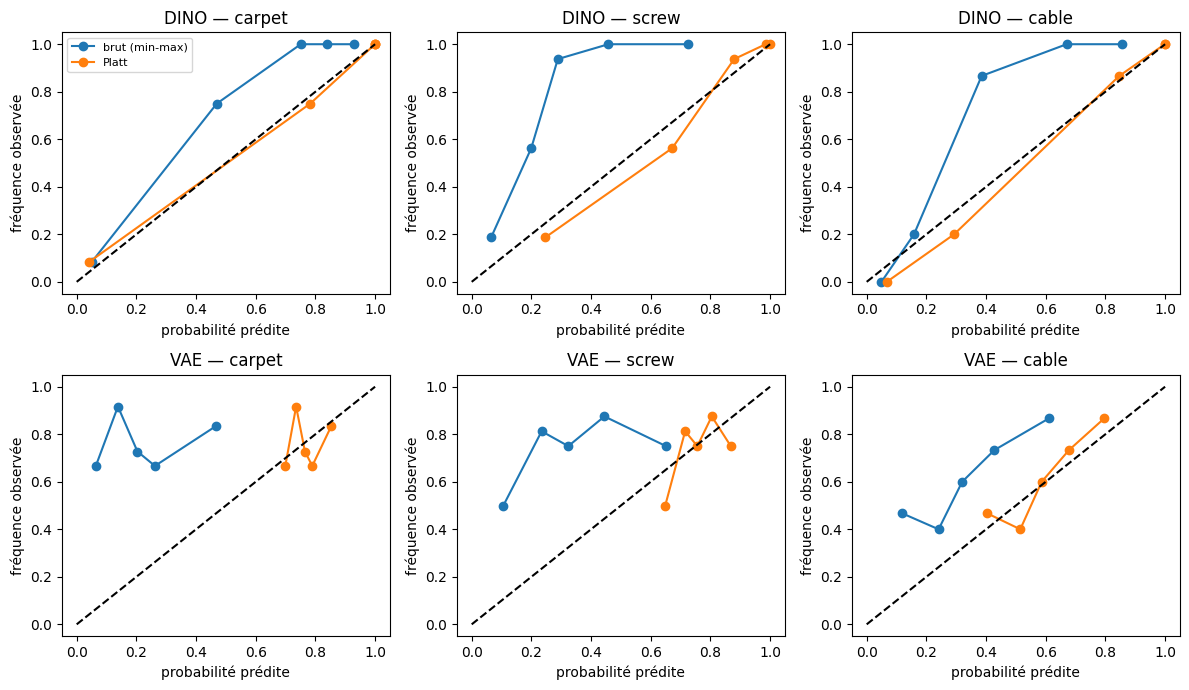

In [11]:
display(cal)
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for r, name in enumerate(MODELS):
    for c, cat in enumerate(CATEGORIES):
        ye, p_raw, p_cal = CURVES[(name, cat)]
        for p, lab in [(p_raw, "brut (min-max)"), (p_cal, "Platt")]:
            frac_pos, mean_pred = calibration_curve(ye, p, n_bins=5, strategy="quantile")
            ax[r, c].plot(mean_pred, frac_pos, "o-", label=lab)
        ax[r, c].plot([0, 1], [0, 1], "k--")
        ax[r, c].set_title(f"{name} — {cat}")
        ax[r, c].set_xlabel("probabilité prédite"); ax[r, c].set_ylabel("fréquence observée")
ax[0, 0].legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{RES_DIR}/t9_reliability.png", dpi=150); plt.show()

**Cellule 6 : heatmaps de succès et d’échecs (DINO)**

Using cache found in /root/.cache/torch/hub/facebookresearch_dino_main


carpet | écart max avec les scores sauvegardés : 0.0
  Vrai positif: 88 image(s)
  Faux négatif: 1 image(s)
  Faux positif: 4 image(s)


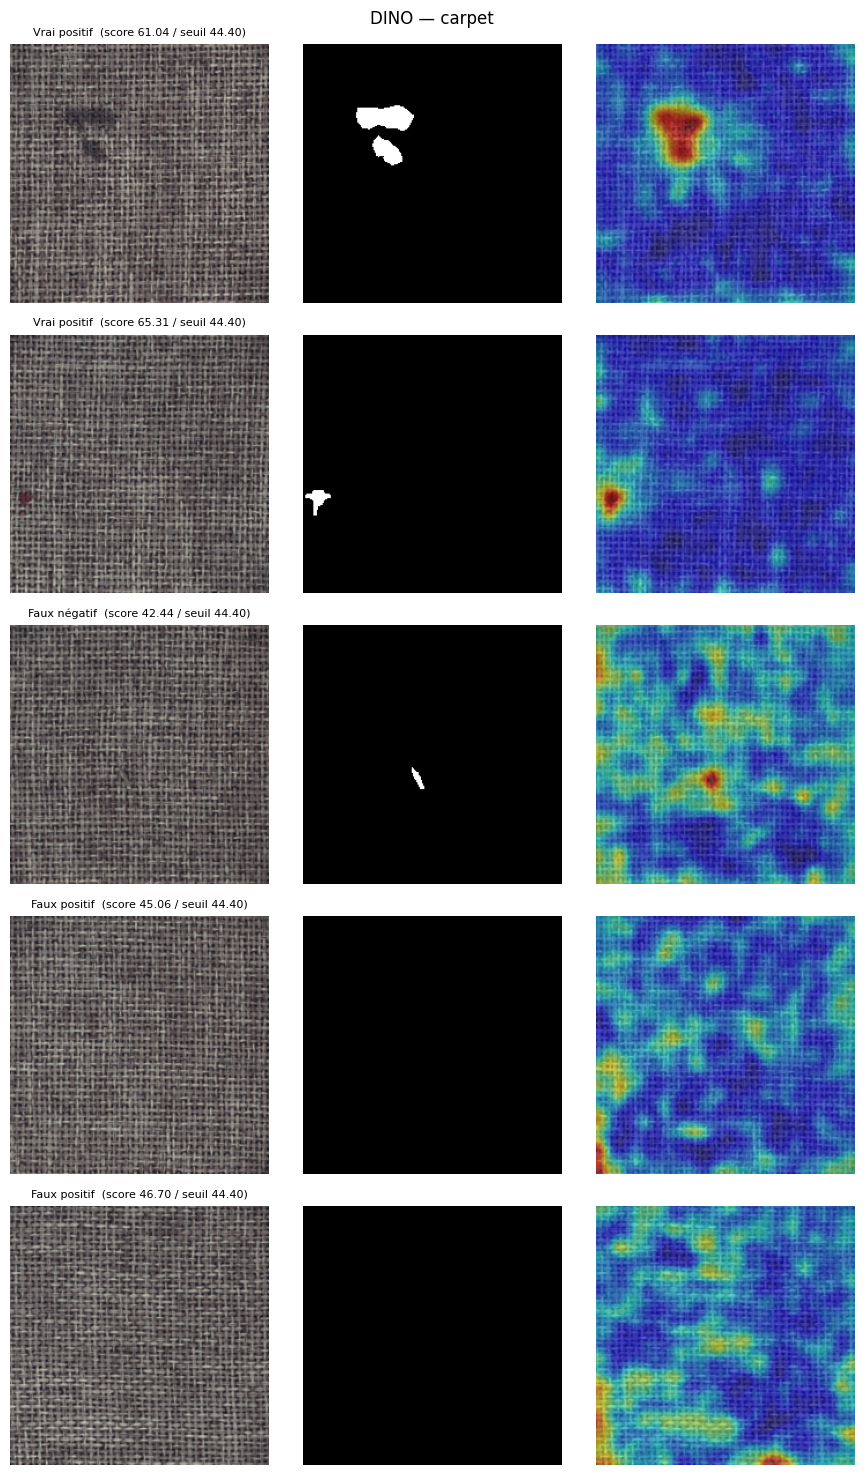

screw | écart max avec les scores sauvegardés : 0.0
  Vrai positif: 97 image(s)
  Faux négatif: 22 image(s)
  Faux positif: 3 image(s)


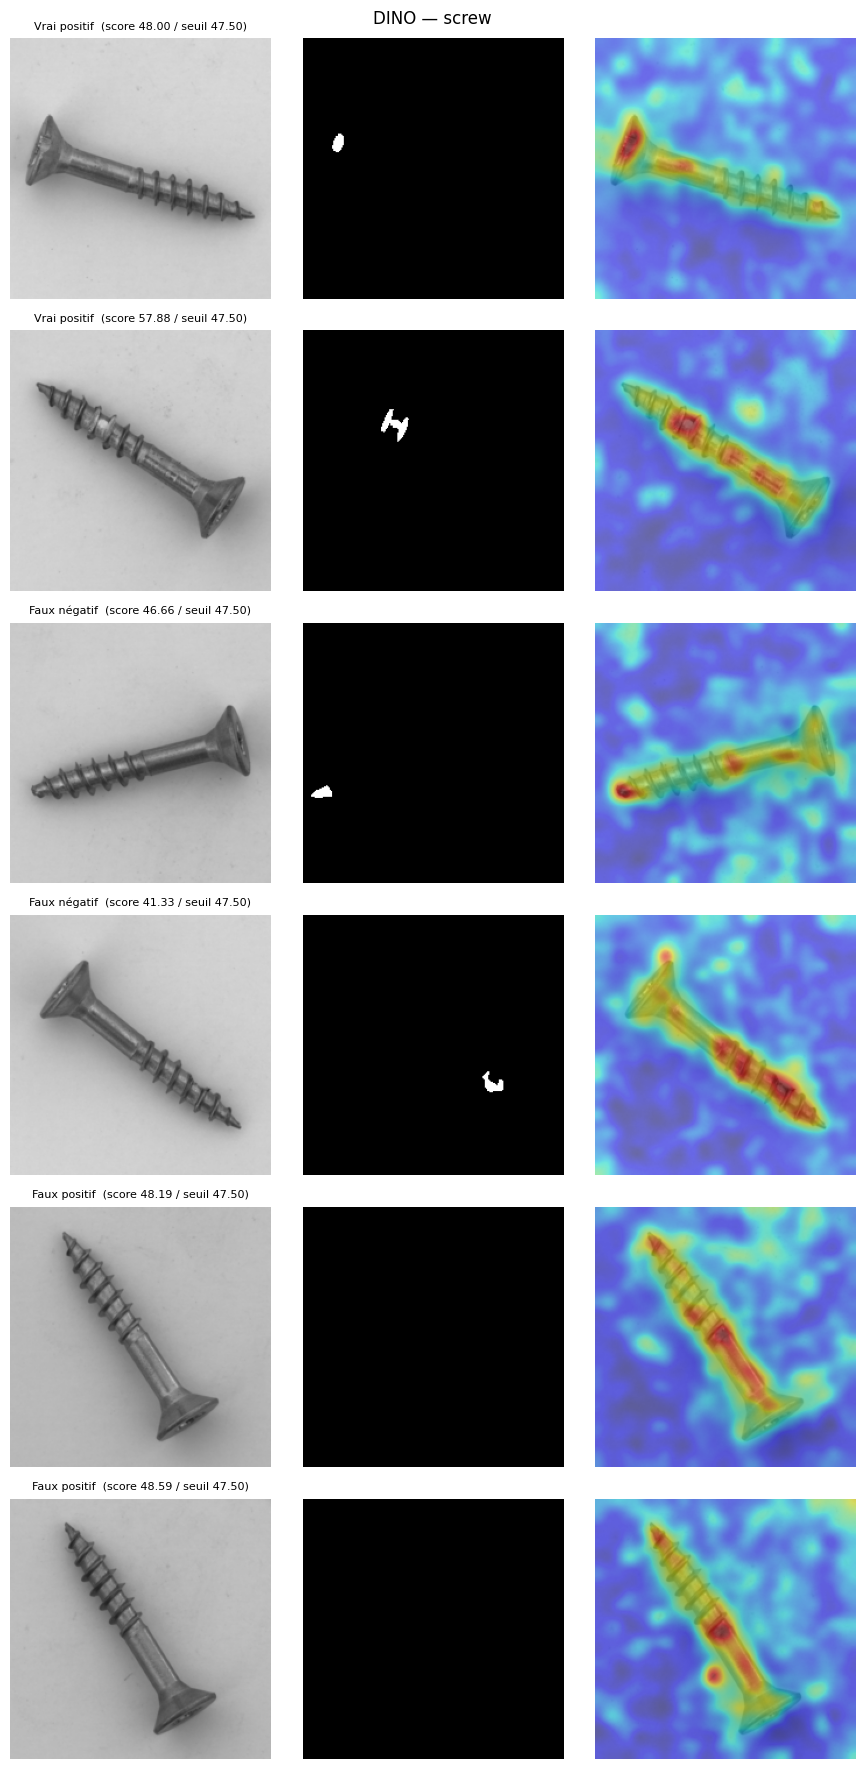

cable | écart max avec les scores sauvegardés : 0.0
  Vrai positif: 86 image(s)
  Faux négatif: 6 image(s)
  Faux positif: 4 image(s)


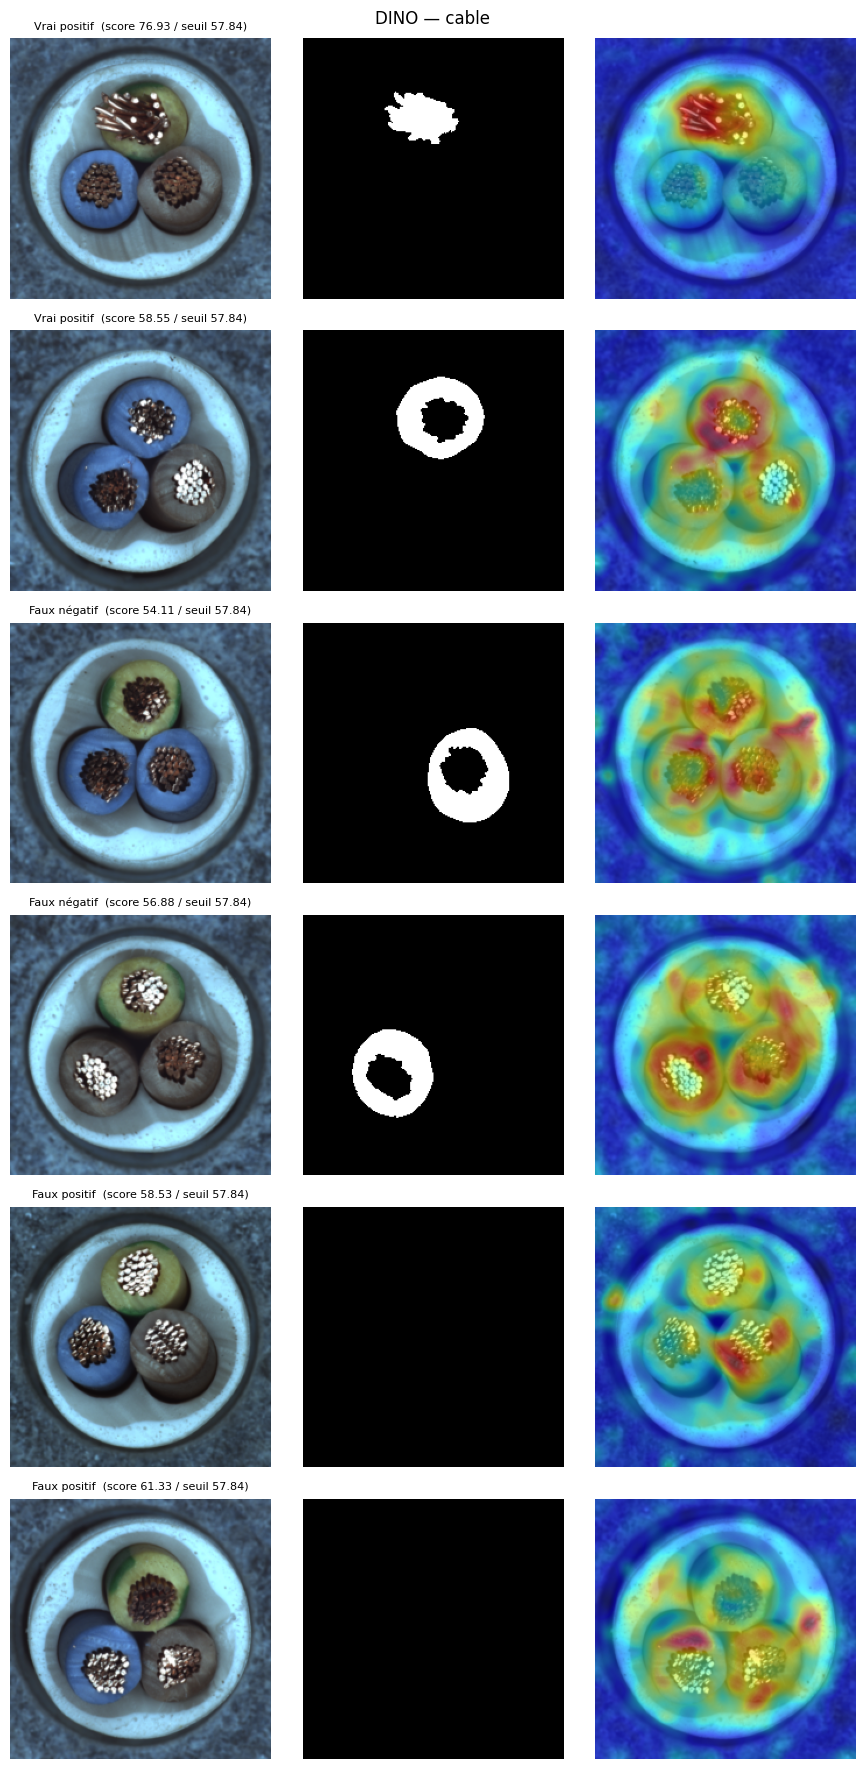

In [12]:
def show_cases(cat, sm_maps, scores, y, thr, ds_disp, n=2, seed=0):
    rng = np.random.RandomState(seed)
    groups = {"Vrai positif": (y == 1) & (scores > thr),
              "Faux négatif": (y == 1) & (scores <= thr),
              "Faux positif": (y == 0) & (scores > thr)}
    picks = []
    for g, m in groups.items():
        idx = np.where(m)[0]
        picks += [(g, i) for i in (rng.choice(idx, min(n, len(idx)), replace=False) if len(idx) else [])]
        print(f"  {g}: {len(idx)} image(s)")
    fig, ax = plt.subplots(len(picks), 3, figsize=(9, 3 * len(picks)), squeeze=False)
    for r, (g, i) in enumerate(picks):
        img, _, m = ds_disp[i]; img = img.permute(1, 2, 0).numpy()
        ax[r, 0].imshow(img); ax[r, 0].set_title(f"{g}  (score {scores[i]:.2f} / seuil {thr:.2f})", fontsize=8)
        ax[r, 1].imshow(m[0], cmap="gray")
        ax[r, 2].imshow(img); ax[r, 2].imshow(sm_maps[i], cmap="jet", alpha=0.5)
        for a in ax[r]: a.axis("off")
    plt.suptitle(f"DINO — {cat}"); plt.tight_layout()
    plt.savefig(f"{RES_DIR}/t9_cases_dino_{cat}.png", dpi=150); plt.show()

det = DinoDetector("dino_vits8", IMG_SIZE, device)
for cat in CATEGORIES:
    tr, _ = list_train_val(DATA_ROOT, cat)
    mk = lambda items: MVTecDataset(items, IMG_SIZE, imagenet_norm=True)
    det.fit(DataLoader(mk(tr), batch_size=32, shuffle=False))
    maps, y, _ = predict_maps(lambda x: det.anomaly_map(x, k=K_MAIN),
                              mk(list_test(DATA_ROOT, cat)), batch_size=16, device=device)
    sm = smooth_maps(maps, SIGMA); sc_ = image_scores_from_maps(sm)
    _, s_saved, v = load_scores("dino", cat)
    print(cat, "| écart max avec les scores sauvegardés :", float(np.abs(sc_ - s_saved).max()))
    show_cases(cat, sm, sc_, y, np.percentile(v, 95), MVTecDataset(list_test(DATA_ROOT, cat), IMG_SIZE))